# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Define Priors

In [3]:
NSamps = 8000;

priorTheta = Array{Any}(undef, 13);
priotY0 = Array{Any}(undef, 3);

priorTheta[1] = Normal(40.92, 10); priorTheta[2] = Normal(51.23, 10); priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

global sampsTh = zeros(NSamps, 13);
global sampsY0 = zeros(NSamps, 3);

Random.seed!(687865443); 

for i in 1:13
    sampsTh[:,i] = rand(priorTheta[i], NSamps);
end
for i in 1:3
    sampsY0[:,i] = rand(priotY0[i], NSamps);
end

sampsTh[:,2] .= 51.23; # T1 of Pyruvate is fixed since it is irrelevant for the model for the problem and can be estimated with experiments without cells. 
sampsTh[:,13] .= 15; # This will be re-writen with the empirical value once extracted from data

In [4]:
bounds = [zeros(12), zeros(12)];
boundY0 = [[0, 0, 0], [1600, 4e4, 1600]];
for i in 1:12
    if i >= 3
        if priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4) >= 0
            bounds[1][i] = priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4);
        else
            bounds[1][i] = 0;
        end
        if priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4) <= 2
            bounds[2][i] = priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4);
        else
            bounds[2][i] = 2;
        end
    elseif i == 1
        bounds[1][i] = priorTheta[i].μ - (priorTheta[i].σ*4);
        bounds[2][i] = priorTheta[i].μ + (priorTheta[i].σ*4);
    elseif i == 2
        bounds[1][i] = 51.23;
        bounds[2][i] = 51.23;
    end
end

In [5]:
# priorInfer =  Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame))
priorInfer =  Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame))

8000×16 Matrix{Float64}:
 41.1949  51.23  0.00772956  0.0186012  …  108.217   29811.1    503.579
 51.6101  51.23  0.00555101  0.0274524      92.1469  26464.8    606.874
 35.1197  51.23  0.00359025  0.022186       99.0307  24812.1   1052.16
 42.6028  51.23  0.00456304  0.0212256      85.5154  19561.7    687.445
 47.9692  51.23  0.00240846  0.0221916     728.696   19468.1     96.2662
 34.1855  51.23  0.00208756  0.0264356  …  966.98    13295.4     51.994
 41.3952  51.23  0.00365566  0.0360747     674.542   13456.3     34.8437
 43.0616  51.23  0.00375345  0.0534735     913.116   13598.4     19.7182
 40.0763  51.23  0.00456141  0.0192255     623.161    8511.54    89.1608
 38.109   51.23  0.00208587  0.0394897     793.988   24283.8     29.0393
  ⋮                                     ⋱                         ⋮
 49.7357  51.23  0.00225835  0.0386458      64.7826  17986.2    729.165
 30.5304  51.23  0.00610859  0.0242321     830.675   16655.5    477.217
 50.8069  51.23  0.00687396  0.02793   

# Optimal Experimental Design (OED)

In [6]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:13];
global sampsY0 = priorInfer[:,14:end];

In [7]:
CompRepUtil_Entro_OEDmc([15.0125])

165.27265644456944

## Optimisation

In [ ]:
steps = 1;

In [ ]:
model = ElasticGPE(steps,                            # 4*2 input dimensions
           mean = MeanConst(0.),
           kernel = SEArd(zeros(steps), 3.),
           logNoise = 0.,
           capacity = 3000);

In [ ]:
modeloptimizer = MAPGPOptimizer(every = 50, noisebounds = [-4, 3],       # bounds of the logNoise
                               kernbounds = [[-1*ones(steps); 0], [4*ones(steps); 10]],  # bounds of the 3 parameters GaussianProcesses.get_param_names(model.kernel)
                               maxeval = 50);

In [ ]:
opt = BOpt(CompRepUtil_Entro_OEDmc,
          model,
          ExpectedImprovement(),                   # type of acquisition            UpperConfidenceBound
          modeloptimizer,
          [0.1],[40.], # lowerbounds, upperbounds
          repetitions = 1,                          # evaluate the function for each input 1 times
          maxiterations = 500,                      # evaluate at 50 input positions
          sense = Max,  
                                      # maximise the function
          acquisitionoptions = (method = :LD_LBFGS, # run optimization of acquisition function with NLopts :LD_LBFGS method
                restarts = 2,       # run the NLopt method from 5 random initial conditions each time.
                maxtime = 0.1,      # run the NLopt method for at most 0.1 second each time
                maxeval = 1000),    # run the NLopt methods for at most 1000 iterations (for other options see https://github.com/JuliaOpt/NLopt.jl
          verbosity = Progress);

In [ ]:
result = boptimize!(opt)

In [14]:
inputOED = result.observed_optimizer

1-element Vector{Float64}:
 0.6149878679370574

In [8]:
inputOED = 0.6149878679370574;

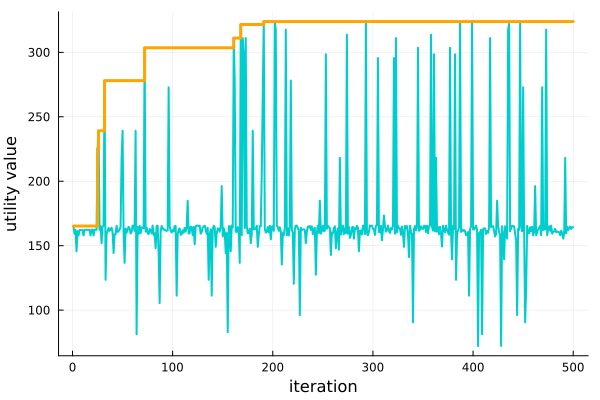

In [15]:
utilb = zeros(length(opt.model.y));
utilb[1] = opt.model.y[1];
for i in 2:length(opt.model.y)
    if opt.model.y[i]>=utilb[i-1]
        utilb[i] = opt.model.y[i];
    else
        utilb[i] = utilb[i-1];
    end
end

plot(opt.model.y, label = "", xlabel = "iteration", ylabel = "utility value", color="cyan3", linewidth = 2)
plot!(1:length(utilb), utilb, label = "", linetype=:step, color="orange", linewidth = 3)

### Save resutls

In [16]:
JLD2.save(string("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\OptimisationResults_Seq\\CRExp_SeqOED_OED1_OEDmc.jld"), "result", result, "inputOED",inputOED)

In [17]:
optres = Dict("acquisitionoptions"=>opt.acquisitionoptions,
                "duration"=>opt.duration,
#                 "func"=>opt.func,
#                 "initializer"=>opt.initializer,
#                 "iterations"=>opt.iterations,
#                 "iterations"=>opt.iterations,
#                 "lowerbounds"=>opt.lowerbounds,
#                 "model"=>opt.model,
                "model_optimizer"=>opt.model_optimizer,
                "model_optimum"=>opt.model_optimum,
                "modeloptimizer"=>opt.modeloptimizer,
                "observed_optimizer"=>opt.observed_optimizer,
                "observed_optimum"=>opt.observed_optimum,
#                 "opt"=>opt.opt,
                "repetitions"=>opt.repetitions,
                "sense"=>opt.sense,
#                 "timeroutput"=>opt.timeroutput,
                "upperbounds"=>opt.upperbounds,
#                 "verbosity"=>opt.verbosity,
                "modelX"=>Array(opt.model.x),
                "modelY"=>Array(opt.model.y));
JLD2.save(string("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\OptimisationResults_Seq\\CRExp_SeqOED_OED1_OEDmc2.jld"), optres)

In [11]:
PyrCons = [round(JLD2.load(string("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\OptimisationResults_Seq\\CRExp_SeqOED_OED1_OEDmc.jld"))["inputOED"][1], digits=1)]

1-element Vector{Float64}:
 0.6

In [10]:
CompRepUtil_Entro_OEDmc([0.6])

323.90686425576286

## Simulate Experiment Prio Prediction

In [12]:
simsPrior = Array{Any}(undef, 8000);

tsC2 = vcat(0, collect(15:5:395));
for i in 1:8000
    ts = 0:tsC2[end];
    ivss = [round(PyrCons[1], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(PyrCons[1], digits = 1)*1000, 0, round(PyrCons[1], digits = 1)*1000*(priorInfer[1,13]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);
    simsPrior[i] = SimulsAll;
end

In [13]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];
for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end

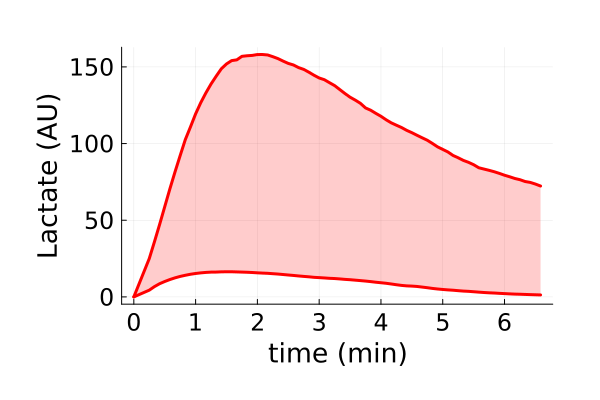

In [14]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "red", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "red", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="red", fillalpha=0.2)

# .................................................... PERFORM EXPERIMENT ....................................................

7.5 uL of pyruvate + 242.5 uL of media from the 20 mM solution 
<br>
3.75 uL of pyruvate + 246.25 uL of media from the 40 mM solution 
<br>
1.875 uL of pyruvate + 248.125 uL of media from the 80 mM solution

# Extract Experimental Data 3.2 mM and 0.6 mM

In [15]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_0-6mMPyr_Dat.csv"];
conce = [3.2, 0.6];

In [16]:
Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1])

Dict{String, Any} with 15 entries:
  "Means"  => [9177.49 1226.15; 6162.55 723.012; … ; -6.00262 0.320623; 5.56735…
  "stsl"   => [77 77]
  "obSta"  => [1 2]
  "sts"    => [0 0; 20 20; … ; 390 390; 395 395]
  "obser"  => 2
  "Y0us"   => [3200.0 600.0; 0.0 0.0; … ; 0.0 0.0; 9177.49 1226.15]
  "ts"     => [1.0e-20 1.0e-20; 1.0 1.0; … ; 394.0 394.0; 395.0 395.0]
  "itp"    => [0.0, 0.0]
  "ScFms"  => [23.8997 17.0298]
  "ncells" => [4 4]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [821.947 81.2187; 491.932 72.3012; … ; 7.38584 4.42203; 6.8147 8.…
  "m"      => 2
  "nts"    => [395 395]

# Simulate Experiment Prior Prediction

In [17]:
simsPrior = Array{Any}(undef, 8000);
sampsTh[:,13] .= dat["ScFms"][end];

tsC2 = dat["sts"];
for i in 1:8000
    tsC2 = dat["sts"][:,end];
    ts = 0:tsC2[end];
    ivss = [round(conce[end], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);

    simsPrior[i] = SimulsAll;
end

In [18]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


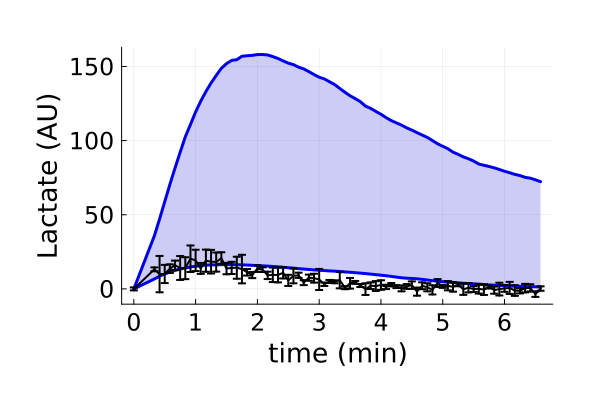

In [19]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "")

# MLE to obtain a good first guess for inference

In [20]:
function ObjectFunctMECp_Multi_MLE(p)

    # Define parameter vectors for each amount of cells (last parameter is a time delay, not used in here)
    
    obj = 0;
    
    for i in 1:length(dat["stsl"])
        pD2 = vcat(p[1:end-3], dat["ScFms"][i], 0);

        # Define time vector
        t2cor = dat["sts"][:,i];

        # Define equaly-spaced time vector
        ts1 = collect(0:t2cor[end]);

        # Define initial value for simulation (use of experimental mean)
        ivss1 = [dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), 0, dat["Means"][1,i,2]/(dat["ScFms"][i]*0.12), p[end-2], p[end-1], p[end], 0, 0, 0, 0, 0, dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), dat["Means"][1,i,2], dat["Means"][1,i,1]];

        # Convert sampling vector to integer to extract correct elements from simulation
        samps1 = convert.(Int, t2cor);

        # Simulate
        SimOnTime1, SimOffTime1, SimAll1  = PyruvateHP_NMR_SolveAllCp(ts1, pD2, ivss1, samps1);
    
        # mm11 = sum((-1/2) .* (log(2*pi) .+ log.((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2) .+ (((SimOnTime1[:,14]/maximum(dat["Means"][:,i,1])) .- 
        #                 (dat["Means"][:,i,1]/maximum(dat["Means"][:,i,1]))).^2)./((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2)));
        mm11 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,1].^2) .+ ((SimOnTime1[:,14] .- dat["Means"][:,i,1]).^2)./(dat["Erros"][:,i,1].^2)));
        mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][:,i,2]).^2)./(dat["Erros"][:,i,2].^2)));
        # println(mm11)
        # obj = (mm21+mm22)*(mm11+mm12);
        if p[end-2] >= p[end-1]
            mm22 = mm22*10;
        end
        # obj = -(mm22)+obj;
        obj = -(mm22)+sqrt(abs(mm11))+obj;
    end
    
    return(obj)

end

ObjectFunctMECp_Multi_MLE (generic function with 1 method)

In [21]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE(p)

2030.6627581098644

In [20]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:12], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*4, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.50 secs, 70 evals, 37 steps, improv/step: 0.432 (last = 0.4324), fitness=1077.501400910
1.01 secs, 120 evals, 68 steps, improv/step: 0.471 (last = 0.5161), fitness=1077.501400910
1.51 secs, 176 evals, 107 steps, improv/step: 0.430 (last = 0.3590), fitness=1077.501400910
2.11 secs, 246 evals, 161 steps, improv/step: 0.422 (last = 0.4074), fitness=867.190225225
2.62 secs, 336 evals, 234 steps, improv/step: 0.389 (last = 0.3151), fitness=840.838893282
3.16 secs, 386 evals, 276 steps, improv/step: 0.377 (last = 0.3095), fitness=840.838893282
3.66 secs, 475 evals, 360 steps, improv/step: 0.336 (last = 0.2024), fitness=840.838893282
4.17 secs, 534 evals, 411 steps, improv/step: 0.316 (last = 0.1765), fitness=840.838893282
4.68 secs, 625 evals, 493 steps, improv/step: 0.298 (last = 0.2073),

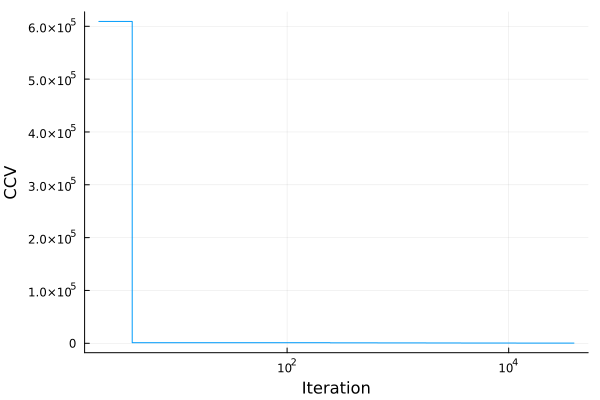

In [30]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

In [22]:
# Extract Parameter Vector
parfitT = zeros(15, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind]

15-element Vector{Float64}:
    34.9893123622788
    51.23
     0.016746362829921983
     0.01884303566551985
     0.06201056744919393
     0.0003798145275649209
     0.05847196853017807
     1.8724891209904735
     1.465209070493244
     0.021404990379637362
     0.21993780144752975
     2.0949451265422703e-5
    92.56558175812683
 33187.38383596008
  1599.5205998447864

In [23]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMTRRCmp_Exper_OED1.jld2", "FitsT",FitsT)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_OED1.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

┌ Warning: Attempting to store var"#89#90".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [23]:
ppT = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_OED1.jld2")["resMMat"][:,1]


15-element Vector{Float64}:
    34.9893123622788
    51.23
     0.016746362829921983
     0.01884303566551985
     0.06201056744919393
     0.0003798145275649209
     0.05847196853017807
     1.8724891209904735
     1.465209070493244
     0.021404990379637362
     0.21993780144752975
     2.0949451265422703e-5
    92.56558175812683
 33187.38383596008
  1599.5205998447864

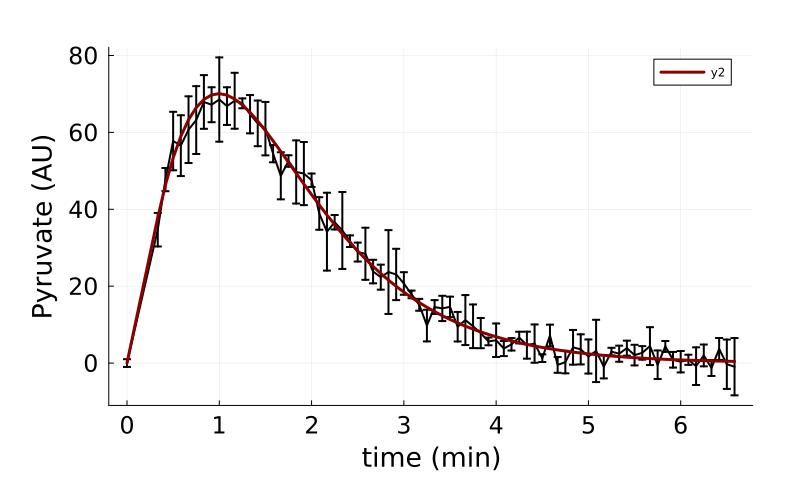

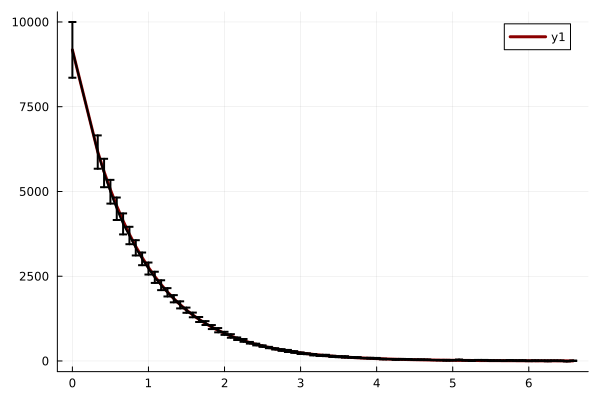

In [24]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,1];
ts = 0:tsC2[end];
ivss = [round(conce[1], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][1], 0), ivss, samps);

pps = plot(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)


ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

display(ps)

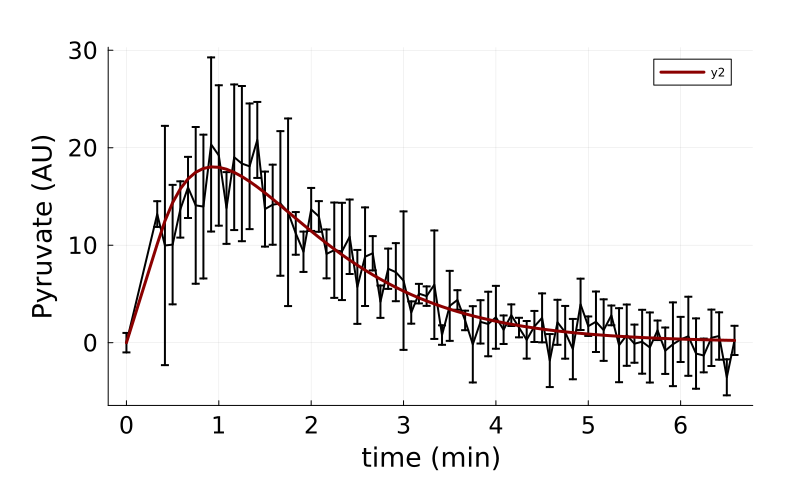

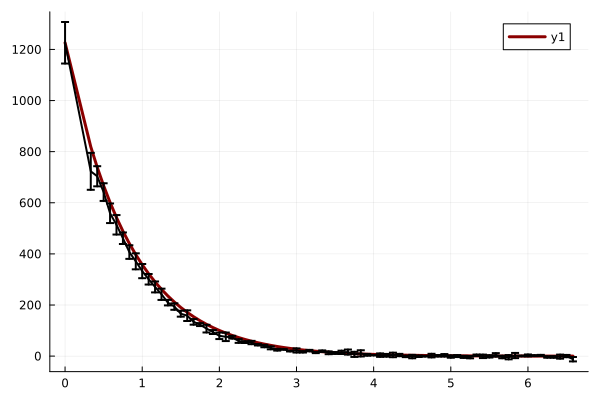

In [25]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,end];
ts = 0:tsC2[end];
ivss = [round(conce[end], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][end], 0), ivss, samps);

pps = plot(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,end]./60, dat["Means"][:,end,1], yerror = dat["Erros"][:,end,1], linewidth = 2, colour = "black", label = "")

display(ps)

## Compute structure for Stan's initial guess

In [26]:
preTrans = zeros(14);

preTrans[1] = (ppT[1]-40.92)/10; 
preTrans[2] = (ppT[3]-0.0055)/0.0055; 
preTrans[3] = (ppT[4]-0.0275)/0.0275;          
preTrans[4] = (ppT[5]-0.045)/0.045;
preTrans[5] = (ppT[6]-0.45)/0.45;
preTrans[6] = (ppT[7]-0.95)/0.95;
preTrans[7] = (ppT[8]-0.95)/0.95;
preTrans[8] = (ppT[9]-0.95)/0.95;
preTrans[9] = (ppT[10]-0.0085)/0.0085;
preTrans[10] = (ppT[11]-0.95)/0.95;
preTrans[11] = (ppT[12]-0.0029)/0.0029;


preTrans[12] = (ppT[13]-650)/260;
preTrans[13] = (ppT[14]-16000)/6400;
preTrans[14] = (ppT[15]-550)/275;

In [27]:

samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict(samps, names, 4)

4-element Vector{Dict{String, Any}}:
 Dict("kbnE" => 1.5182341623102777, "LDH" => 3.8164385448901323, "kin" => 2.044793241803997, "ki" => -0.7684865247920739, "kunE" => 0.5423253373613094, "kpl" => -0.3147987030720055, "NADH" => -2.143978531699512, "kup" => 0.9710411799899722, "T1_X" => -0.5930687637721199, "kbp" => -0.9384505594419178…)
 Dict("kbnE" => 1.5182341623102777, "LDH" => 3.8164385448901323, "kin" => 2.044793241803997, "ki" => -0.7684865247920739, "kunE" => 0.5423253373613094, "kpl" => -0.3147987030720055, "NADH" => -2.143978531699512, "kup" => 0.9710411799899722, "T1_X" => -0.5930687637721199, "kbp" => -0.9384505594419178…)
 Dict("kbnE" => 1.5182341623102777, "LDH" => 3.8164385448901323, "kin" => 2.044793241803997, "ki" => -0.7684865247920739, "kunE" => 0.5423253373613094, "kpl" => -0.3147987030720055, "NADH" => -2.143978531699512, "kup" => 0.9710411799899722, "T1_X" => -0.5930687637721199, "kbp" => -0.9384505594419178…)
 Dict("kbnE" => 1.5182341623102777, "LDH" => 3.8164385

In [28]:
ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 1.51823
  "LDH"  => 3.81644
  "kin"  => 2.04479
  "ki"   => -0.768487
  "kunE" => 0.542325
  "kpl"  => -0.314799
  "NADH" => -2.14398
  "kup"  => 0.971041
  "T1_X" => -0.593069
  "kbp"  => -0.938451
  "kr"   => -0.992776
  "NAD"  => 2.68553
  "kun"  => -0.999156
  "kbn"  => 0.378013

# Inference

In [29]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_OED1_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 600, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [ ]:
# modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit2.stan";

In [30]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_OED1_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(600,600,600,600,600,600,600,600,600,600); thin=(1,1,1,1,1,1,1,1,1,1); 14000 iterations saved.

Warmup took (50066, 47667, 47841, 47971, 49356, 50224, 50559, 51984, 48815, 49769) seconds, 137 hours total
Sampling took (64847, 55901, 53476, 58467, 62013, 62334, 64015, 59080, 53864, 55272) seconds, 164 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -3.9e+02  6.2e-02  3.0e+00  -4.0e+02  -3.9e+02  -3.9e+02  2.4e+03  4.1e-03  1.0e+00
accept_stat__    9.6e-01  7.4e-04  6.8e-02   8.3e-01   9.9e-01      1.00  8.4e+03  1.4e-02  1.0e+00
stepsize__       7.0e-03  3.3e-04  2.1e-03   3.8e-03   6.9e-03     0.011  4.1e+01  7.0e-05  1.1e+00
treedepth__      9.0e+00  5.6e-02  6.4e-01   8.0e+00   9.0e+00        10  1.3e+02  2.2e-04  1.0e+00
n_leapfrog__     6.5e+02  2.0e+01  2.7e+02   2.6e+02  

(0, [-394.463 0.978186 … 16554.8 1361.34; -394.463 0.0 … 16554.8 1361.34; … ; -390.953 0.997717 … 13177.5 1453.66; -390.554 0.997204 … 18583.7 860.17;;; -401.753 0.598057 … 6708.08 1594.54; -401.753 0.0 … 6708.08 1594.54; … ; -388.995 0.999968 … 29352.9 1451.71; -388.692 0.984515 … 29785.3 1440.16;;; -408.938 0.992623 … 7154.68 1599.97; -408.938 0.0 … 7154.68 1599.97; … ; -390.508 0.99987 … 6183.61 1232.93; -387.126 0.999248 … 7534.2 1127.11;;; -404.739 0.962502 … 5764.75 1594.06; -404.739 0.0 … 5764.75 1594.06; … ; -393.176 0.995504 … 11312.1 1160.85; -391.069 0.911354 … 19058.2 1505.78;;; -402.475 0.979752 … 4568.35 1584.09; -402.475 0.0 … 4568.35 1584.09; … ; -388.439 0.96735 … 20490.7 1283.09; -395.381 0.997781 … 19007.5 1177.38;;; -408.864 0.994136 … 5450.56 1597.35; -408.864 0.0 … 5450.56 1597.35; … ; -389.981 0.999011 … 17619.7 1528.57; -394.838 0.999996 … 14340.3 1574.8;;; -400.203 0.987688 … 4974.49 1236.86; -400.203 0.0 … 4974.49 1236.86; … ; -388.794 0.960127 … 14483.6 1120.

In [34]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PyrCompetitiveRepressionInferExp_OED1_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [35]:
poster = vcat(chns[601:end, end-15:end, 1], chns[601:end, end-15:end, 2], chns[601:end, end-15:end, 3], chns[601:end, end-15:end, 4], chns[601:end, end-15:end, 5], 
              chns[601:end, end-15:end, 6], chns[601:end, end-15:end, 7], chns[601:end, end-15:end, 8], chns[601:end, end-15:end, 9], chns[601:end, end-15:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv"

In [36]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv", DataFrame))

8000×16 Matrix{Float64}:
 47.0209  51.23  0.0190752  0.0202484  …   373.041   21480.2  1430.41
 44.1484  51.23  0.0220342  0.0189998      563.724   14004.7   961.492
 48.8478  51.23  0.019956   0.0204499      243.162   22831.6  1237.69
 48.0088  51.23  0.019155   0.0214141      214.067   15227.8  1383.03
 50.3595  51.23  0.0213304  0.022624        88.1227  12370.1  1213.07
 37.9966  51.23  0.0145974  0.0167566  …  1200.8     27107.1  1241.38
 46.2821  51.23  0.0176245  0.0208012      156.076   12126.9  1170.18
 50.494   51.23  0.0194389  0.021762       271.178   19480.3  1017.7
 38.4183  51.23  0.0187112  0.0173605      953.664   17309.0  1370.89
 36.0838  51.23  0.0184488  0.0168619      955.243   13801.5  1343.43
  ⋮                                    ⋱                         ⋮
 44.8391  51.23  0.0187946  0.0186503      513.46    24671.9  1228.26
 45.7868  51.23  0.0185363  0.0189395      485.299   24551.6  1218.76
 40.036   51.23  0.0195125  0.0184574      696.903   16123.2  1313.8

# Plot Posterior VS Prior

In [37]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [38]:
priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

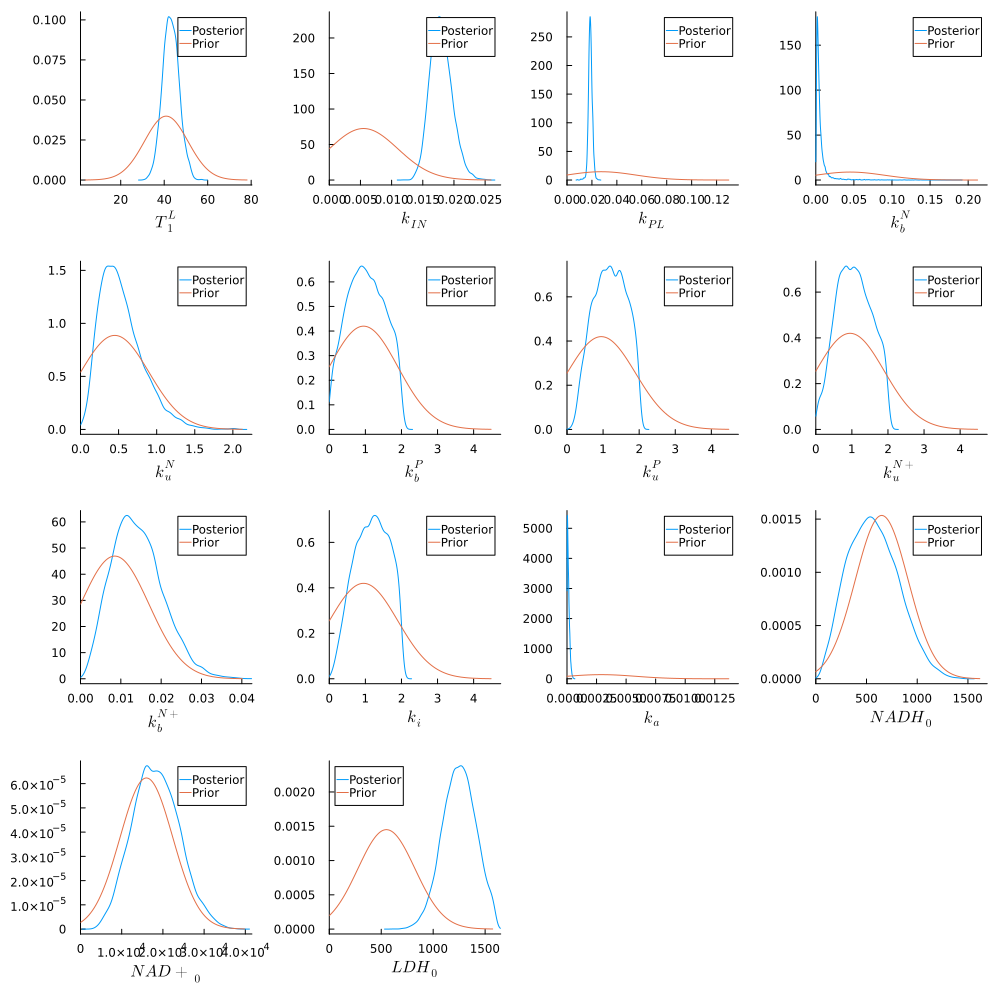

In [39]:
pp0 = plot(kde(poster[:,1]), label = "Posterior", xlabel = namess[1])
plot!(Normal(40.92, 10), label = "Prior")

pp1 = plot(kde(poster[:,3]), label = "Posterior", xlabel = namess[2])
plot!(Normal(0.0055, 0.0055), label = "Prior", xlim = (0, 0.0055+4*0.0055))

pp2 = plot(kde(poster[:,4]), label = "Posterior", xlabel = namess[3])
plot!(Normal(0.0275, 0.0275), label = "Prior", xlim = (0, 0.0275+4*0.0275))

pp3 = plot(kde(poster[:,5]), label = "Posterior", xlabel = namess[4])
plot!(Normal(0.045, 0.045), label = "Prior", xlim = (0, 0.045+4*0.045))

pp4 = plot(kde(poster[:,6]), label = "Posterior", xlabel = namess[5])
plot!(Normal(0.45, 0.45), label = "Prior", xlim = (0, 0.45+4*0.45))

pp5 = plot(kde(poster[:,7]), label = "Posterior", xlabel = namess[6])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp6 = plot(kde(poster[:,8]), label = "Posterior", xlabel = namess[7])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp7 = plot(kde(poster[:,9]), label = "Posterior", xlabel = namess[8])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp8 = plot(kde(poster[:,10]), label = "Posterior", xlabel = namess[9])
plot!(Normal(0.0085, 0.0085), label = "Prior", xlim = (0, 0.0085+4*0.0085))

pp9 = plot(kde(poster[:,11]), label = "Posterior", xlabel = namess[10])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp10 = plot(kde(poster[:,12]), label = "Posterior", xlabel = namess[11])
plot!(Normal(0.0029, 0.0029), label = "Prior", xlim = (0, 0.0029+4*0.0029))


pp11 = plot(kde(poster[:,14]), label = "Posterior", xlabel = namess[12])
plot!(Normal(650, 260), label = "Prior", xlim = (0, 650+4*260))

pp12 = plot(kde(poster[:,15]), label = "Posterior", xlabel = namess[13])
plot!(Normal(16000, 6400), label = "Prior", xlim = (0, 16000+4*6400))

pp13 = plot(kde(poster[:,16]), label = "Posterior", xlabel = namess[14])
plot!(Normal(550, 275), label = "Prior", xlim = (0, 550+4*275))

plot(pp0,pp1,pp2,pp3,pp4,pp5,pp6,pp7,pp8,pp9,pp10,pp11,pp12,pp13, size=(1000,1000), grid = false)

In [40]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,14:end]))))

35.372606513330666

In [41]:
using CairoMakie
using PairPlots
using DataFrames

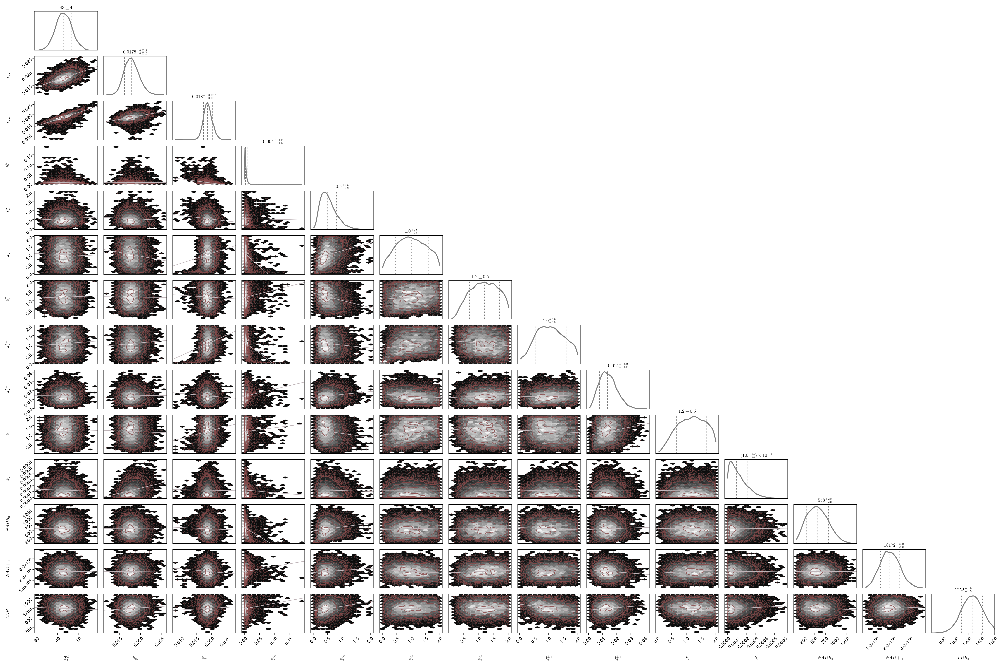

In [42]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,14:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_OED1Experiment.svg", fig)


fig

# Simulate Experiment Current Posterior

In [66]:
simsPoster = Array{Any}(undef, 8000, 2);

for j in 1:2
for i in 1:8000
    tsC2 = dat["sts"][:,j];
    ts = 0:tsC2[end];
    ivss = [dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, 0, poster[i,14], poster[i,15], poster[i,16], 0, 0, 0, 0, 0, dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, dat["Means"][1,j,1]];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster[i,1:12], dat["ScFms"][j], 0), ivss, samps);

    simsPoster[i,j] = SimulsAll;
end
end

### Experiment 1

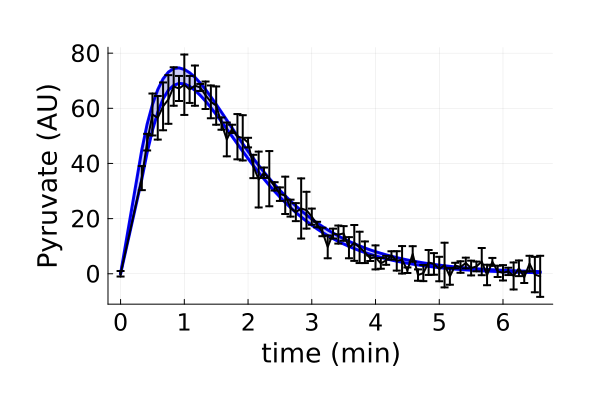

In [ ]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,1][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")

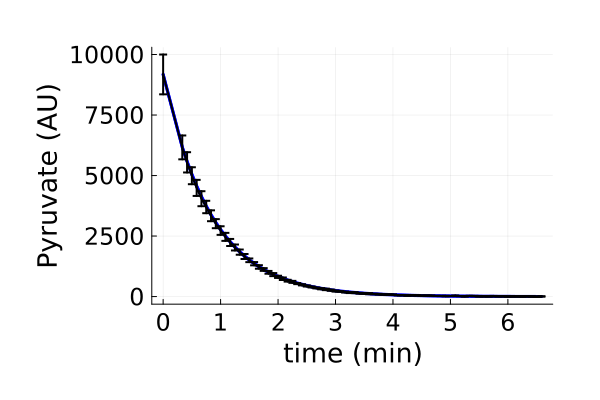

In [ ]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,1][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

## Experiment 2

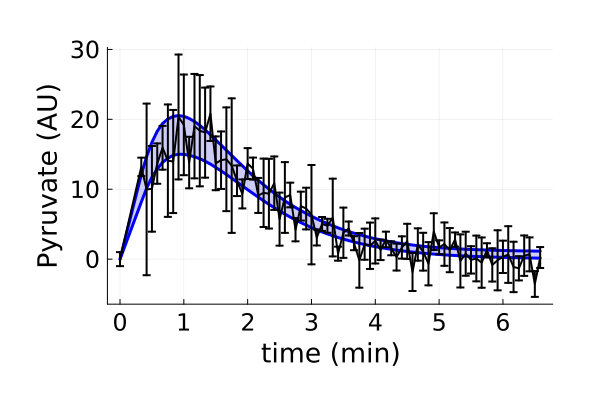

In [77]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,2][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "")

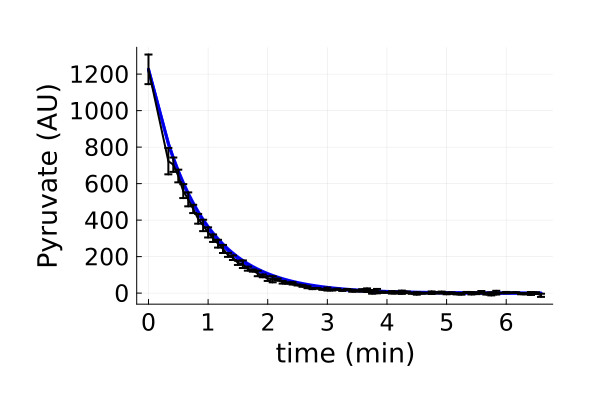

In [80]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,2][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")